# Chapter 2: The Importance of Data

Companion notebook for Chapter 2 of *Mastering AI-Powered Finance* (`Overleaf/Book 1`). It was built from Chapter 2 of the full manuscript (The Importance of Data); the source references below point to that manuscript.

Notebook extracted from `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`.

This notebook turns the chapter code examples into a student-facing workflow. Code cells follow the order used in the chapter; Markdown cells identify the source section and preserve sample output blocks from the LaTeX when present.

Run the notebook from top to bottom. Some examples are intentionally small and synthetic; examples that call external services require the dependency or credential noted below.

**External requirements for some cells:** internet market-data access.

Reviewed against `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`. Source-line references below identify the original extraction, while the runnable examples include corrections and extra teaching detail. Sample output blocks are historical illustrations, not expected assertions: synthetic data and market downloads produce different numbers.

The first cleaning examples demonstrate **alternative treatments** on copies of one small dataset. They are descriptive exercises, not a model validation pipeline. For predictive work, split first and fit imputers, outlier thresholds, bin boundaries, scalers and text vocabularies only on the training data (and again inside each cross-validation fold). The loan tutorial demonstrates this separation.

In [1]:
# Common notebook setup
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.grid'] = True
# Grayscale defaults, matching the printed book: black, mid and light gray,
# each with its own line style so series stay distinguishable in print.
from cycler import cycler
plt.rcParams['axes.prop_cycle'] = cycler(color=['0.0', '0.45', '0.7'], linestyle=['-', '--', ':'])
plt.rcParams['image.cmap'] = 'Greys'

import seaborn as sns

from pathlib import Path
Path('outputs').mkdir(exist_ok=True)

## Reproducible setup for standalone snippets
The first chapter examples are small cleaning fragments. This synthetic DataFrame gives those fragments the columns they expect before the later market-data examples create their own `df`.

In [2]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
df = pd.DataFrame({
    'pe_ratio': [18.5, np.nan, 24.2, 31.0, np.nan, 15.7],
    'some_feature': [1.0, np.nan, 0.7, 0.8, np.nan, 1.2],
    'sector': ['Tech', 'Tech', 'Finance', 'Finance', 'Utilities', 'Utilities'],
    'price': [100.0, np.nan, 102.5, np.nan, 105.0, 106.0],
    'interest_rate': [0.045, np.nan, 0.047, np.nan, 0.050, 0.051],
    'market_cap': [1200, np.nan, 900, 700, np.nan, 500],
    'assets': [3000, 2500, np.nan, 1800, 1500, np.nan],
    'revenue': [400, 380, 250, np.nan, 160, 140],
    'feature1': [1, np.nan, 3, 4, 5, 6],
    'feature2': [2, 3, np.nan, 5, 6, 7],
    'feature3': [3, 4, 5, np.nan, 7, 8],
    'returns': rng.normal(0.001, 0.02, 6),
    'volume': [1_200_000, 950_000, 1_400_000, 1_100_000, 2_000_000, 870_000],
    'trading_volume': [1_200_000, 950_000, 1_400_000, 1_100_000, 2_000_000, 870_000],
})
cleaning_df = df.copy()
df

,pe_ratio,some_feature,sector,price,interest_rate,market_cap,assets,revenue,feature1,feature2,feature3,returns,volume,trading_volume
0,18.5,1.0,Tech,100.0,0.045,1200.0,3000.0,400.0,1.0,2.0,3.0,0.007094,1200000,1200000
1,NaN,NaN,Tech,NaN,NaN,NaN,2500.0,380.0,NaN,3.0,4.0,-0.019800,950000,950000
2,24.2,0.7,Finance,102.5,0.047,900.0,NaN,250.0,3.0,NaN,5.0,0.016009,1400000,1400000
3,31.0,0.8,Finance,NaN,NaN,700.0,1800.0,NaN,4.0,5.0,NaN,0.019811,1100000,1100000
4,NaN,NaN,Utilities,105.0,0.050,NaN,1500.0,160.0,5.0,6.0,7.0,-0.038021,2000000,2000000
5,15.7,1.2,Utilities,106.0,0.051,500.0,NaN,140.0,6.0,7.0,8.0,-0.025044,870000,870000


## Data Cleaning and Processing / Handling Missing Data / Deletion methods

### Code example 1
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [3]:
# Complete-case deletion is an alternative, not an input to subsequent imputation demos.
complete_case_df = cleaning_df.dropna(subset=['pe_ratio'])
complete_case_df

,pe_ratio,some_feature,sector,price,interest_rate,market_cap,assets,revenue,feature1,feature2,feature3,returns,volume,trading_volume
0,18.5,1.0,Tech,100.0,0.045,1200.0,3000.0,400.0,1.0,2.0,3.0,0.007094,1200000,1200000
2,24.2,0.7,Finance,102.5,0.047,900.0,NaN,250.0,3.0,NaN,5.0,0.016009,1400000,1400000
3,31.0,0.8,Finance,NaN,NaN,700.0,1800.0,NaN,4.0,5.0,NaN,0.019811,1100000,1100000
5,15.7,1.2,Utilities,106.0,0.051,500.0,NaN,140.0,6.0,7.0,8.0,-0.025044,870000,870000


### Code example 2
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [4]:
# Evaluate the missingness threshold before any rows have been deleted.
column_filtered_df = cleaning_df.copy()
if column_filtered_df['some_feature'].isnull().mean() > 0.3:
    column_filtered_df = column_filtered_df.drop(columns=['some_feature'])
column_filtered_df

,pe_ratio,sector,price,interest_rate,market_cap,assets,revenue,feature1,feature2,feature3,returns,volume,trading_volume
0,18.5,Tech,100.0,0.045,1200.0,3000.0,400.0,1.0,2.0,3.0,0.007094,1200000,1200000
1,NaN,Tech,NaN,NaN,NaN,2500.0,380.0,NaN,3.0,4.0,-0.019800,950000,950000
2,24.2,Finance,102.5,0.047,900.0,NaN,250.0,3.0,NaN,5.0,0.016009,1400000,1400000
3,31.0,Finance,NaN,NaN,700.0,1800.0,NaN,4.0,5.0,NaN,0.019811,1100000,1100000
4,NaN,Utilities,105.0,0.050,NaN,1500.0,160.0,5.0,6.0,7.0,-0.038021,2000000,2000000
5,15.7,Utilities,106.0,0.051,500.0,NaN,140.0,6.0,7.0,8.0,-0.025044,870000,870000


## Data Cleaning and Processing / Handling Missing Data / Single imputation

### Code example 3
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [5]:
# Fill missing P/E with its sector median on the original sample.
median_imputed_df = cleaning_df.copy()
median_imputed_df['pe_ratio'] = median_imputed_df['pe_ratio'].fillna(
    median_imputed_df.groupby('sector')['pe_ratio'].transform('median')
)
median_imputed_df

,pe_ratio,some_feature,sector,price,interest_rate,market_cap,assets,revenue,feature1,feature2,feature3,returns,volume,trading_volume
0,18.5,1.0,Tech,100.0,0.045,1200.0,3000.0,400.0,1.0,2.0,3.0,0.007094,1200000,1200000
1,18.5,NaN,Tech,NaN,NaN,NaN,2500.0,380.0,NaN,3.0,4.0,-0.019800,950000,950000
2,24.2,0.7,Finance,102.5,0.047,900.0,NaN,250.0,3.0,NaN,5.0,0.016009,1400000,1400000
3,31.0,0.8,Finance,NaN,NaN,700.0,1800.0,NaN,4.0,5.0,NaN,0.019811,1100000,1100000
4,15.7,NaN,Utilities,105.0,0.050,NaN,1500.0,160.0,5.0,6.0,7.0,-0.038021,2000000,2000000
5,15.7,1.2,Utilities,106.0,0.051,500.0,NaN,140.0,6.0,7.0,8.0,-0.025044,870000,870000


### Code example 4
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [6]:
# Capture missingness before imputation; this is an alternative to sector medians.
df = cleaning_df.copy()
df['pe_ratio_was_missing'] = df['pe_ratio'].isnull().astype(int)
df['pe_ratio'] = df['pe_ratio'].fillna(-1)
df[['pe_ratio', 'pe_ratio_was_missing']]

,pe_ratio,pe_ratio_was_missing
0,18.5,0
1,-1.0,1
2,24.2,0
3,31.0,0
4,-1.0,1
5,15.7,0


## Data Cleaning and Processing / Handling Missing Data / Time-series imputation

### Code example 5
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [7]:
# Interpret these rows as ordered observations of ONE illustrative price series.
# Carrying a price forward is suitable for valuation, but creates stale marks.
# Do not treat the resulting zero returns as observed trading returns.
df['price'] = df['price'].ffill()

### Code example 6
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [8]:
# Retrospective interpolation uses a future endpoint and is NOT causal.
# For a forecasting feature, use an available historical value, e.g. ffill().
df['interest_rate_interpolated'] = df['interest_rate'].interpolate(method='linear')
df['interest_rate'] = df['interest_rate'].ffill()

## Data Cleaning and Processing / Handling Missing Data / Advanced, model-based imputation

### Code example 7
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [9]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

# Scale observed values first so assets do not dominate revenue in distances.
# This is a tiny descriptive demo; fit both objects on training data for modeling.
numeric_cols = ['market_cap', 'assets', 'revenue']
knn_scaler = StandardScaler()
scaled_numeric = knn_scaler.fit_transform(df[numeric_cols])
imputer = KNNImputer(n_neighbors=3)
df[numeric_cols] = knn_scaler.inverse_transform(imputer.fit_transform(scaled_numeric))

### Code example 8
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [10]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

imputer = IterativeImputer(max_iter=10, random_state=0)
numeric_cols = ['feature1', 'feature2', 'feature3']
df[numeric_cols] = imputer.fit_transform(df[numeric_cols])

## Data Cleaning and Processing / Outliers

### Code example 9
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [11]:
# Identify outliers using the Interquartile Range (IQR) rule
Q1 = df['returns'].quantile(0.25)
Q3 = df['returns'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['returns'] < lower_bound) | (df['returns'] > upper_bound)]

### Code example 10
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [12]:
# Calculate the robust z-score for a series
from scipy.stats import median_abs_deviation

median = df['returns'].median()
# Calculate MAD for the non-missing values
mad = median_abs_deviation(df['returns'].dropna())
# A zero MAD has no usable scale; leave scores undefined rather than divide by zero.
df['robust_z'] = (0.6745 * (df['returns'] - median) / mad
                  if np.isfinite(mad) and mad > 0 else np.nan)

### Code example 11
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [13]:
# Use Isolation Forest for multi-dimensional outlier detection
from sklearn.ensemble import IsolationForest

# Select features to use for detection, dropping any rows with NaNs
features = df[['returns', 'volume']].dropna()

iso_forest = IsolationForest(contamination='auto', random_state=42)
# fit_predict returns -1 for outliers and 1 for inliers
outlier_preds = iso_forest.fit_predict(features)
features['is_outlier'] = outlier_preds

## Data Cleaning and Processing / Outliers / What to do about them

### Code example 12
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [14]:
# Fix a known decimal slip on a specific date when that date exists in the dataset
error_date = '2025-09-18'
if error_date in df.index:
    df.loc[error_date, 'price'] = df.loc[error_date, 'price'] / 10
else:
    print(f'{error_date} is not present in this sample; no correction applied.')

2025-09-18 is not present in this sample; no correction applied.


### Code example 13
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [15]:
# Drop a row corresponding to a non-repairable error
if error_date in df.index:
    df.drop(index=error_date, inplace=True)
else:
    print(f'{error_date} is not present in this sample; no row dropped.')

2025-09-18 is not present in this sample; no row dropped.


### Code example 14
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [16]:
# Cap returns at the 1st and 99th percentiles
lower_b = df['returns'].quantile(0.01)
upper_b = df['returns'].quantile(0.99)
df['returns_capped'] = df['returns'].clip(lower=lower_b, upper=upper_b)

### Code example 15
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [17]:
import numpy as np
# Calculate log returns (this does not guarantee stationary or constant-variance returns)
df['log_returns'] = np.log(df['price'] / df['price'].shift(1))

## Data Cleaning and Processing / Handling Imbalanced Data / Under-sampling the majority class

### Code example 16
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

## Reproducible setup for class imbalance examples
The following synthetic transaction data supports the undersampling and SMOTE examples.

In [18]:
# Synthetic fraud dataset for class imbalance examples
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
n = 500
df = pd.DataFrame({
    'transaction_amount': rng.lognormal(mean=3.4, sigma=0.8, size=n),
    'account_age_days': rng.integers(10, 3000, size=n),
    'transactions_24h': rng.poisson(2, size=n),
    'distance_from_home': rng.exponential(20, size=n),
})
fraud_score = (
    0.025 * df['transactions_24h']
    + 0.006 * df['distance_from_home']
    + 0.0008 * df['transaction_amount']
    + rng.normal(0, 0.2, size=n)
)
threshold = np.quantile(fraud_score, 0.88)
df['is_fraud'] = (fraud_score > threshold).astype(int)
df['is_fraud'].value_counts()

# Reserve an untouched test set BEFORE any resampling.
# This synthetic sample is IID; real transaction streams require temporal splits.
from sklearn.model_selection import train_test_split
fraud_train, fraud_test = train_test_split(
    df, test_size=0.25, stratify=df['is_fraud'], random_state=42
)

In [19]:
from sklearn.utils import resample

# Separate majority and minority classes
df_majority = fraud_train[fraud_train['is_fraud'] == 0]
df_minority = fraud_train[fraud_train['is_fraud'] == 1]

# Undersample majority class to match minority class
df_majority_undersampled = resample(
    df_majority,
    replace=False,  # Sample without replacement
    n_samples=len(df_minority),  # Match minority class size
    random_state=42
)

# Combine minority class with undersampled majority class
df_balanced = pd.concat([df_majority_undersampled, df_minority])

## Data Cleaning and Processing / Handling Imbalanced Data / Oversampling the minority class

### Code example 17
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [20]:
# Oversample minority class to match majority class
df_minority_oversampled = resample(
    df_minority,
    replace=True,  # Sample with replacement (allows duplicates)
    n_samples=len(df_majority),  # Match majority class size
    random_state=42
)

# Combine oversampled minority class with majority class
df_balanced = pd.concat([df_majority, df_minority_oversampled])

## Data Cleaning and Processing / Handling Imbalanced Data / SMOTE (Synthetic Minority Over-sampling Technique)

### Code example 18
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [21]:
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler

# Only training observations may influence neighbor selection or synthetic rows.
X = fraud_train.drop('is_fraud', axis=1)
y = fraud_train['is_fraud']
smote_scaler = StandardScaler()
X_scaled = smote_scaler.fit_transform(X)
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_scaled, y)
# Convert back to original units for inspection, not to imply real transactions.
X_resampled_original = pd.DataFrame(smote_scaler.inverse_transform(X_resampled), columns=X.columns)
# Model inputs X_resampled and X_test_scaled share the same scaled units.
X_test_scaled = smote_scaler.transform(fraud_test.drop('is_fraud', axis=1))

print(f"Training class distribution: {y.value_counts().to_dict()}")
print(f"Resampled training distribution: {pd.Series(y_resampled).value_counts().to_dict()}")
print(f"Untouched test distribution: {fraud_test['is_fraud'].value_counts().to_dict()}")
# SMOTE interpolates counts too: fractional account ages / transaction counts
# are synthetic modeling features, not valid observed transaction records.

Training class distribution: {0: 330, 1: 45}
Resampled training distribution: {0: 330, 1: 330}
Untouched test distribution: {0: 110, 1: 15}


## Exploratory Data Analysis / Univariate Analysis: Profiling a Single Variable

These examples download adjusted Yahoo Finance prices for 2020–2024, with Kaggle-style column names. Retained numerical output blocks and figures in this EDA section are historical presentation illustrations, not asserted results for this download. Executing the notebook produces the current statistics and plots.


### Code example 19
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [22]:
import os
from pathlib import Path

import yfinance as yf
import pandas as pd

# The tickers we want
tickers = ["AAPL", "MSFT", "GOOGL"]

# Fixed dates keep the 2024 examples available on future runs. Adjusted OHLC
# explicitly includes corporate-action adjustments; prices are not raw quotes.
# The bundled snapshot keeps the statistics below reproducible: auto_adjust
# back-adjusts the whole history on every dividend, so a live download drifts
# after publication. Set REFRESH_MARKET_DATA=1 to fetch current data instead.
SNAPSHOT = Path("data/prices_2020_2024.csv")
if SNAPSHOT.exists() and os.environ.get("REFRESH_MARKET_DATA") != "1":
    raw = pd.read_csv(SNAPSHOT, header=[0, 1], index_col=0, parse_dates=True)
else:
    raw = yf.download(tickers, start="2020-01-01", end="2025-01-01", interval="1d",
                      group_by="ticker", auto_adjust=True, progress=False)
if raw is None or raw.empty:
    raise RuntimeError("Market data unavailable; check the bundled snapshot or internet access.")

frames = []  # store each ticker's cleaned frame

for t in tickers:
    # Extract this ticker's columns
    if t not in raw.columns.get_level_values(0):
        raise RuntimeError(f"Market download did not include {t}.")
    df_t = raw[t].copy()
    if df_t["Close"].notna().sum() < 42:
        raise RuntimeError(f"Insufficient usable price history for {t}.")

    # Keep Kaggle columns and reset index
    df_t = df_t[["Open", "High", "Low", "Close", "Volume"]].reset_index()

    # Rename to Kaggle-style names
    df_t = df_t.rename(
        columns={
            "Date": "date",
            "Open": "open",
            "High": "high",
            "Low": "low",
            "Close": "close",
            "Volume": "volume",
        }
    )

    # Add ticker name
    df_t["Name"] = t
    frames.append(df_t)

# Combine all tickers into one DataFrame
df_all = pd.concat(frames, ignore_index=True)

# Convert date column to datetime and set as index (matches Kaggle behavior)
df_all["date"] = pd.to_datetime(df_all["date"])
df = df_all.set_index("date").sort_index()

aapl = df[df["Name"] == "AAPL"][["close", "volume"]].copy()
aapl["daily_return"] = aapl["close"].pct_change(fill_method=None)

## Exploratory Data Analysis / Univariate Analysis: Profiling a Single Variable / Central tendency

### Code example 20
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [23]:
# Mini-case — Trading Volume (instead of revenue)
mean_volume = aapl["volume"].mean()
median_volume = aapl["volume"].median()  # Often more representative
print(f"Mean Volume:    {mean_volume:,.0f}")
print(f"Median Volume:  {median_volume:,.0f} (More typical day)\n")

Mean Volume:    90,571,035
Median Volume:  76,283,350 (More typical day)



### Sample output or non-executable listing
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

```text
Mean Volume:    71,288,189
Median Volume:  64,718,900 (More typical day)
```

## Exploratory Data Analysis / Univariate Analysis: Profiling a Single Variable / Dispersion

### Code example 21
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [24]:
# Mini-case — Realized Volatility (using daily returns)
std_dev = aapl["daily_return"].std()
q3 = aapl["daily_return"].quantile(0.75)
q1 = aapl["daily_return"].quantile(0.25)
iqr = q3 - q1
print(f"Standard Deviation of Returns: {std_dev:.4f}")
print(f"Interquartile Range (IQR):    {iqr:.4f} (Robust measure of spread)")

Standard Deviation of Returns: 0.0200
Interquartile Range (IQR):    0.0204 (Robust measure of spread)


### Sample output or non-executable listing
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

```text
Standard Deviation of Returns: 0.0177
Interquartile Range (IQR):    0.0181 (Robust measure of spread)
```

## Exploratory Data Analysis / Univariate Analysis: Profiling a Single Variable / Shape: skew and tails

### Code example 22
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

Skewness: 0.1056
Kurtosis: 5.2778 (> 0 indicates fatter tails than a normal distribution)



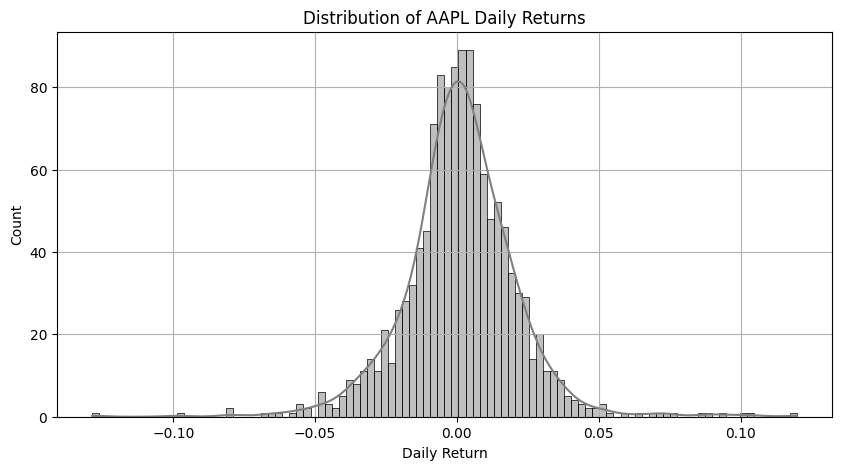

In [25]:
# Check for asymmetry and fat tails in daily returns
skewness = aapl["daily_return"].skew()
kurtosis = aapl["daily_return"].kurtosis()

print(f"Skewness: {skewness:.4f}")
print(
    f"Kurtosis: {kurtosis:.4f} (> 0 indicates fatter tails than a normal distribution)\n"
)


# Visualize the distribution
sns.histplot(aapl["daily_return"].dropna(), kde=True, bins=100, color="0.5")
plt.title("Distribution of AAPL Daily Returns")
plt.xlabel("Daily Return")
# save the figure
plt.savefig("aapl_daily_returns_distribution.pdf", dpi=300, bbox_inches="tight")
plt.show()

### Sample output or non-executable listing
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

```text
Skewness: 0.4544
Kurtosis: 6.2801 (> 0 indicates fatter tails than a normal distribution)
```

## Exploratory Data Analysis / Bi-variate Analysis: Uncovering Relationships

### Code example 23
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [26]:
# Pivot the data to get tickers as columns
price_df = df.pivot(columns="Name", values="close")[["AAPL", "MSFT"]]

# Mini-case: Shared drift
# 1. High correlation in prices due to a common trend
price_corr = price_df.corr(method="pearson")
print("--- Correlation of Prices ---")
print(price_corr)

# 2. Return correlation measures co-movement without relying on shared price trends
return_corr = price_df.pct_change(fill_method=None).corr(method="pearson")
print("\n--- Correlation of Returns ---")
print(return_corr)

--- Correlation of Prices ---
Name      AAPL      MSFT
Name                    
AAPL  1.000000  0.930175
MSFT  0.930175  1.000000

--- Correlation of Returns ---
Name      AAPL      MSFT
Name                    
AAPL  1.000000  0.748328
MSFT  0.748328  1.000000


### Sample output or non-executable listing
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

```text
--- Correlation of Prices ---
Name      AAPL      MSFT
Name                    
AAPL  1.000000  0.904437
MSFT  0.904437  1.000000

--- Correlation of Returns ---
Name      AAPL      MSFT
Name                    
AAPL  1.000000  0.635897
MSFT  0.635897  1.000000
```

## Exploratory Data Analysis / Bi-variate Analysis: Uncovering Relationships / Seeing the relationship

### Code example 24
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

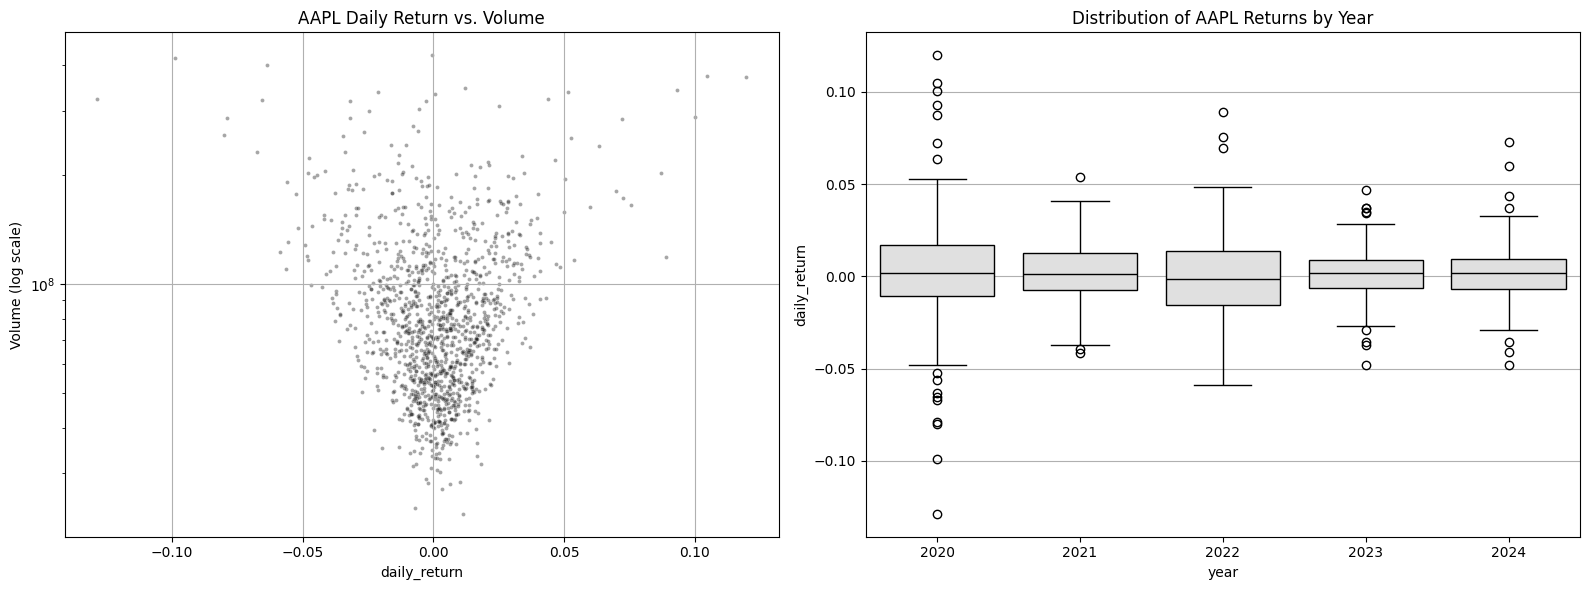

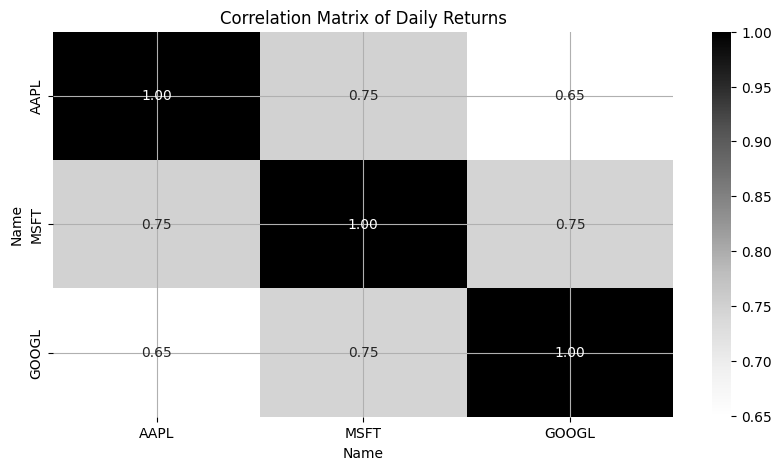

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Scatter plot for two continuous variables (return vs. volume)
sns.scatterplot(data=aapl, x="daily_return", y="volume", ax=axes[0],
                color="black", alpha=0.35, s=8)
axes[0].set_title("AAPL Daily Return vs. Volume")
axes[0].set_ylabel("Volume (log scale)")
axes[0].set_yscale("log")

# Box plot for a categorical and a continuous variable
# We'll create a 'year' category for this example
aapl_returns_by_year = aapl.copy()
aapl_returns_by_year["year"] = aapl_returns_by_year.index.year
sns.boxplot(data=aapl_returns_by_year, x="year", y="daily_return", ax=axes[1],
            color="0.88", linecolor="black")
axes[1].set_title("Distribution of AAPL Returns by Year")
# save the figure
plt.savefig(
    "aapl_return_vs_volume_and_yearly_boxplot.pdf", dpi=300, bbox_inches="tight"
)
plt.tight_layout()
plt.show()

# Heatmap for an overview of many variables
return_matrix = df.pivot(columns="Name", values="close")[tickers].pct_change(fill_method=None)
correlation_matrix = return_matrix.corr()
sns.heatmap(correlation_matrix, annot=True, cmap="Greys", fmt=".2f")
plt.title("Correlation Matrix of Daily Returns")
# save the figure
plt.savefig("correlation_matrix_heatmap.pdf", dpi=300, bbox_inches="tight")
plt.show()

## Exploratory Data Analysis / Time-Series Exploration: Market Dynamics Over Time / Components you can often isolate

### Code example 25
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

Decomposing Trading Volume into Trend, Seasonality, and Residuals


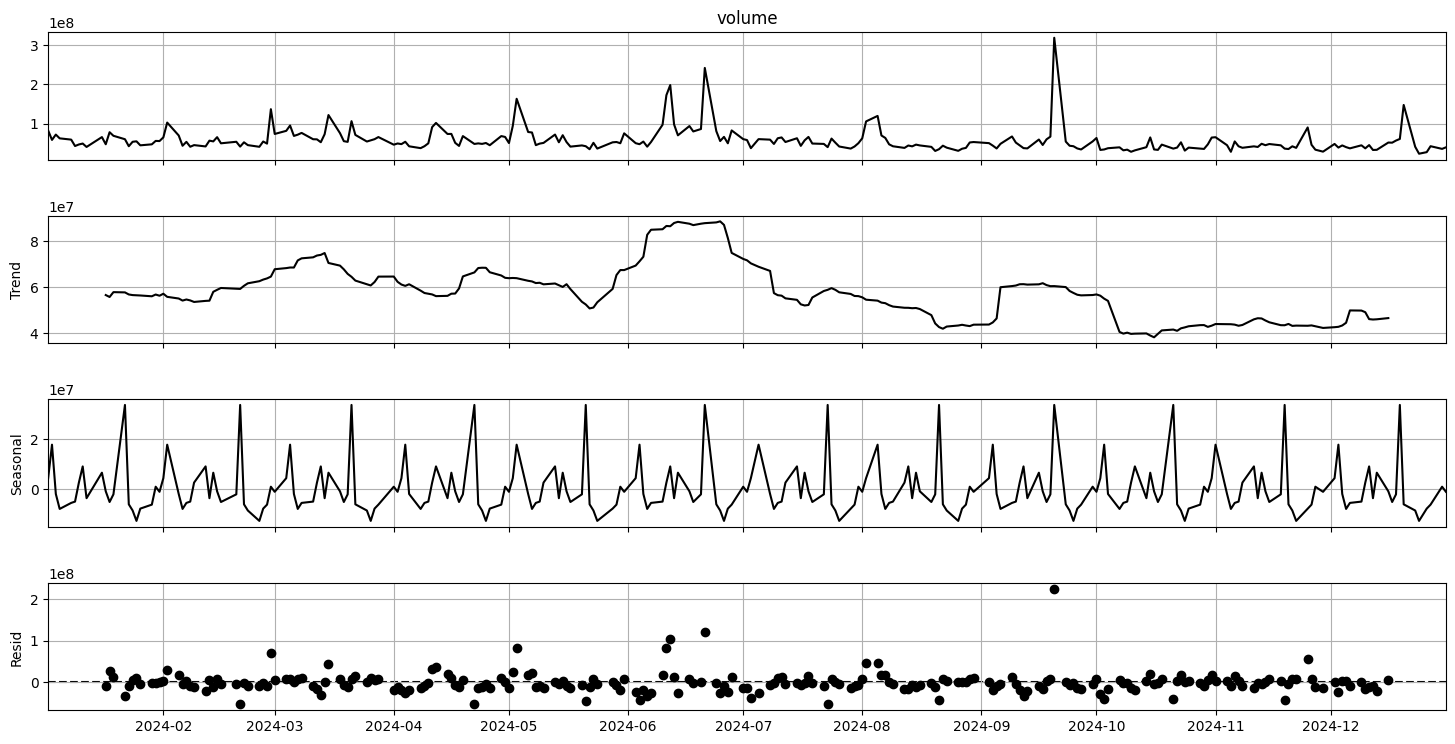

In [28]:
from statsmodels.tsa.seasonal import seasonal_decompose

aapl_indexed = aapl.copy()

# Decompose daily trading volume
# Illustrate a fixed 21-session cycle; this is NOT an exact calendar month.
# The default two-sided trend is retrospective, not a forecasting feature.
# We'll use a subset of the data for a clearer plot
aapl_indexed.index = pd.to_datetime(aapl_indexed.index)

volume_subset = aapl_indexed["volume"]["2024-01-01":"2024-12-31"].dropna()
if len(volume_subset) < 42:
    raise ValueError("Volume decomposition requires at least two 21-session cycles.")
result = seasonal_decompose(volume_subset, model="additive", period=21)

print("Decomposing Trading Volume into Trend, Seasonality, and Residuals")
fig = result.plot()
fig.set_size_inches(15, 8)
# save the figure
plt.savefig("aapl_volume_decomposition.pdf", dpi=300, bbox_inches="tight")
plt.show()

## Exploratory Data Analysis / Time-Series Exploration: Market Dynamics Over Time / Memory and regimes

### Code example 26
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

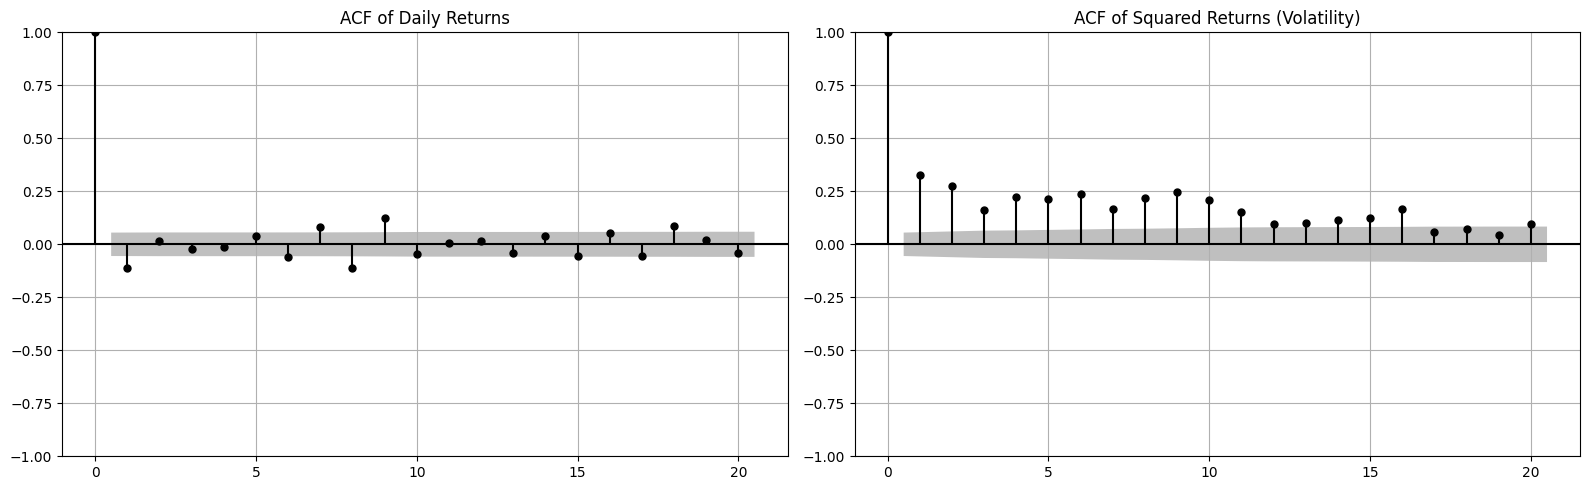

In [29]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Prepare squared returns to check for volatility clustering
aapl["sq_returns"] = aapl["daily_return"] ** 2

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# ACF of returns often shows little to no memory
plot_acf(
    aapl["daily_return"].dropna(), lags=20, ax=axes[0], title="ACF of Daily Returns"
)

# ACF of squared returns shows memory (volatility clustering)
plot_acf(
    aapl["sq_returns"].dropna(),
    lags=20,
    ax=axes[1],
    title="ACF of Squared Returns (Volatility)",
)
# save the figure
plt.savefig("aapl_acf_returns_and_squared_returns.pdf", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

## Exploratory Data Analysis / Time-Series Exploration: Market Dynamics Over Time / Calendars and alignment

### Code example 27
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [30]:
print("Original data with weekend gaps:")
print(aapl["close"].loc["2024-01-01":"2024-01-10"])

# Weekday frequency is NOT an exchange calendar; it inserts market holidays.
# Carry marks forward only for valuation. Keep return calculations on original quotes.
# Resample to weekday frequency
business_day_prices = aapl["close"].resample("B").last()

# Forward-fill any gaps created by holidays (e.g., Jan 1, 2024 was a holiday)
business_day_prices_filled = business_day_prices.ffill()
print("\nResampled and forward-filled data:")
print(business_day_prices_filled.loc["2024-01-01":"2024-01-10"])

Original data with weekend gaps:
date
2024-01-02    183.404007
2024-01-03    182.030746
2024-01-04    179.718933
2024-01-05    178.997711
2024-01-08    183.324966
2024-01-09    182.910049
2024-01-10    183.947372
Name: close, dtype: float64

Resampled and forward-filled data:
date
2024-01-01    190.211014
2024-01-02    183.404007
2024-01-03    182.030746
2024-01-04    179.718933
2024-01-05    178.997711
2024-01-08    183.324966
2024-01-09    182.910049
2024-01-10    183.947372
Freq: B, Name: close, dtype: float64


### Sample output or non-executable listing
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

```text
Original data with weekend gaps:
date
2024-01-02    183.903214
2024-01-03    182.526215
2024-01-04    180.208115
2024-01-05    179.484924
2024-01-08    183.823959
2024-01-09    183.407898
2024-01-10    184.448074
Name: close, dtype: float64

Resampled and forward-filled data:
date
2024-01-01    190.728775
2024-01-02    183.903214
2024-01-03    182.526215
2024-01-04    180.208115
2024-01-05    179.484924
2024-01-08    183.823959
2024-01-09    183.407898
2024-01-10    184.448074
Freq: B, Name: close, dtype: float64
```

## Feature Engineering / Numerical Data / Continuous Data

### Code example 28
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [31]:
from sklearn.preprocessing import StandardScaler

# Small standalone example for scaling heterogeneous financial features
scaling_df = pd.DataFrame({
    'trading_volume': [1_200_000, 950_000, 1_400_000, 1_100_000, 2_000_000],
    'pe_ratio': [18.5, 21.0, 24.2, 31.0, 15.7],
})

scaler = StandardScaler()
scaled_features = scaler.fit_transform(scaling_df[['trading_volume', 'pe_ratio']])

# The output is a NumPy array, which can be converted back to a DataFrame
df_scaled = pd.DataFrame(scaled_features, columns=['volume_scaled', 'pe_scaled'])
df_scaled

,volume_scaled,pe_scaled
0,-0.355664,-0.679602
1,-1.039634,-0.205020
2,0.191511,0.402446
3,-0.629252,1.693310
4,1.833038,-1.211134


### Code example 29
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [32]:
import numpy as np

# Standalone log transform example
feature_df = pd.DataFrame({'market_cap': [500, 1200, 9000, 25000, 180000]})
feature_df['market_cap_log'] = np.log1p(feature_df['market_cap'])
feature_df

,market_cap,market_cap_log
0,500,6.216606
1,1200,7.090910
2,9000,9.105091
3,25000,10.126671
4,180000,12.100718


### Code example 30
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [33]:
# Create 4 bins of equal width for a debt-to-income ratio example
dti_df = pd.DataFrame({'dti_ratio': [0.12, 0.24, 0.31, 0.43, 0.56, 0.72]})
dti_df['dti_binned'] = pd.cut(
    dti_df['dti_ratio'], bins=4, labels=['Low', 'Medium', 'High', 'Very High']
)
dti_df

,dti_ratio,dti_binned
0,0.12,Low
1,0.24,Low
2,0.31,Medium
3,0.43,High
4,0.56,High
5,0.72,Very High


### Code example 31
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [34]:
from sklearn.preprocessing import PolynomialFeatures

macro_df = pd.DataFrame({
    'interest_rate': [0.03, 0.04, 0.045, 0.05, 0.055],
    'inflation': [0.02, 0.028, 0.034, 0.031, 0.026],
})

poly = PolynomialFeatures(degree=2, include_bias=False, interaction_only=False)
inter_features = poly.fit_transform(macro_df[['interest_rate', 'inflation']])
pd.DataFrame(inter_features, columns=poly.get_feature_names_out(['interest_rate', 'inflation']))

,interest_rate,inflation,interest_rate^2,interest_rate inflation,inflation^2
0,0.030,0.020,0.000900,0.00060,0.000400
1,0.040,0.028,0.001600,0.00112,0.000784
2,0.045,0.034,0.002025,0.00153,0.001156
3,0.050,0.031,0.002500,0.00155,0.000961
4,0.055,0.026,0.003025,0.00143,0.000676


## Feature Engineering / Numerical Data / Discrete Data

### Code example 32
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [35]:
# Group loan terms into broader categories
loan_df = pd.DataFrame({'loan_term_months': [36, 84, 180, 240, 360]})
bins = [0, 120, 240, 361]  # <=10yr, 10-20yr, >20yr
labels = ['Short-Term', 'Mid-Term', 'Long-Term']
loan_df['loan_term_group'] = pd.cut(loan_df['loan_term_months'], bins=bins, labels=labels)
loan_df

,loan_term_months,loan_term_group
0,36,Short-Term
1,84,Short-Term
2,180,Mid-Term
3,240,Mid-Term
4,360,Long-Term


### Code example 33
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [36]:
# Convert a count of late payments into a binary flag
payment_df = pd.DataFrame({'num_late_payments': [0, 1, 0, 3, 2]})
payment_df['had_late_payments'] = (payment_df['num_late_payments'] > 0).astype(int)
payment_df

,num_late_payments,had_late_payments
0,0,0
1,1,1
2,0,0
3,3,1
4,2,1


## Feature Engineering / Categorical Data / Nominal Data

### Code example 34
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [37]:
# Create binary columns for each unique sector value
sector_df = pd.DataFrame({'sector': ['Technology', 'Healthcare', 'Finance', 'Technology']})
one_hot_df = pd.get_dummies(sector_df['sector'], prefix='sector')
sector_df = sector_df.join(one_hot_df)
sector_df

,sector,sector_Finance,sector_Healthcare,sector_Technology
0,Technology,False,False,True
1,Healthcare,False,True,False
2,Finance,True,False,False
3,Technology,False,False,True


## Feature Engineering / Categorical Data / Ordinal Data

### Code example 35
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [38]:
# Define the explicit order of risk-rating categories
rating_df = pd.DataFrame({'risk_rating': ['Low', 'Medium', 'High', 'Very High']})
rating_map = {'Low': 1, 'Medium': 2, 'High': 3, 'Very High': 4}
rating_df['risk_rating_ordinal'] = rating_df['risk_rating'].map(rating_map)
rating_df

,risk_rating,risk_rating_ordinal
0,Low,1
1,Medium,2
2,High,3
3,Very High,4


### Code example 36
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [39]:
# Out-of-fold target encoding on a tiny independent sample.
# With temporal data, use past-only folds instead of this shuffled IID split.
from sklearn.model_selection import KFold
encoding_df = pd.DataFrame({
    'risk_rating': ['Low', 'Low', 'Medium', 'High', 'Very High', 'High'],
    'default_rate': [0, 0, 0, 1, 1, 0],
})
encoding_df['risk_rating_encoded'] = np.nan
for fit_idx, heldout_idx in KFold(n_splits=3, shuffle=True, random_state=42).split(encoding_df):
    fold_train = encoding_df.iloc[fit_idx]
    target_map = fold_train.groupby('risk_rating')['default_rate'].mean()
    encoding_df.loc[heldout_idx, 'risk_rating_encoded'] = (
        encoding_df.iloc[heldout_idx]['risk_rating'].map(target_map)
        .fillna(fold_train['default_rate'].mean())
    )
# A separate test set would use a map fitted on the FULL training set only.
encoding_df

,risk_rating,default_rate,risk_rating_encoded
0,Low,0,0.5
1,Low,0,0.5
2,Medium,0,0.5
3,High,1,0.0
4,Very High,1,0.0
5,High,0,1.0


## Feature Engineering / Date and Time

### Code example 37
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [40]:
# Ensure the index is a datetime object
df.index = pd.to_datetime(df.index)

# Extract time-based and cyclical features
df['day_of_week'] = df.index.dayofweek  # Monday=0, Sunday=6
df['month'] = df.index.month
df['quarter'] = df.index.quarter
df['is_month_end'] = df.index.is_month_end
# df['is_trading_holiday'] = df.index.map(is_holiday_func) # Conceptual

### Code example 38
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [41]:
# Calculate loan age and days since last payment
date_df = pd.DataFrame({
    'origination_date': ['2020-01-15', '2021-06-01', '2023-03-20'],
    'last_payment_date': ['2025-08-25', '2025-09-01', '2025-09-20'],
})
date_df['origination_date'] = pd.to_datetime(date_df['origination_date'])
date_df['last_payment_date'] = pd.to_datetime(date_df['last_payment_date'])
as_of_date = pd.to_datetime('2025-09-25')
date_df['loan_age_days'] = (as_of_date - date_df['origination_date']).dt.days
date_df['days_since_last_payment'] = (as_of_date - date_df['last_payment_date']).dt.days
date_df
# Days past due requires the oldest unpaid scheduled due date, not last payment.

,origination_date,last_payment_date,loan_age_days,days_since_last_payment
0,2020-01-15,2025-08-25,2080,31
1,2021-06-01,2025-09-01,1577,24
2,2023-03-20,2025-09-20,920,5


### Code example 39
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [42]:
# Localize timestamps to the original time zone and convert to UTC
trade_df = pd.DataFrame({
    'trade_time': pd.to_datetime(['2025-09-25 09:30', '2025-09-25 10:15', '2025-09-25 15:59'])
})
trade_df['trade_time_local'] = trade_df['trade_time'].dt.tz_localize('US/Eastern', ambiguous='infer')
trade_df['trade_time_utc'] = trade_df['trade_time_local'].dt.tz_convert('UTC')
trade_df

,trade_time,trade_time_local,trade_time_utc
0,2025-09-25 09:30:00,2025-09-25 09:30:00-04:00,2025-09-25 13:30:00+00:00
1,2025-09-25 10:15:00,2025-09-25 10:15:00-04:00,2025-09-25 14:15:00+00:00
2,2025-09-25 15:59:00,2025-09-25 15:59:00-04:00,2025-09-25 19:59:00+00:00


## Feature Engineering / Time-Series Data

### Code example 40
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [43]:
# Features available BEFORE the current observation: shift before rolling.
# Integer windows count observations (sessions), not calendar days.
price_df = pd.DataFrame({'price': [100, 101, 102, 101, 103, 105, 104, 106, 107, 108]})
price_df['price_lag_1'] = price_df['price'].shift(1)
price_df['price_lag_5'] = price_df['price'].shift(5)
price_df['rolling_mean_7_sessions'] = price_df['price'].shift(1).rolling(window=7).mean()
price_df['rolling_std_7_sessions'] = price_df['price'].shift(1).rolling(window=7).std()
price_df

,price,price_lag_1,price_lag_5,rolling_mean_7_sessions,rolling_std_7_sessions
0,100,NaN,NaN,NaN,NaN
1,101,100.0,NaN,NaN,NaN
2,102,101.0,NaN,NaN,NaN
3,101,102.0,NaN,NaN,NaN
4,103,101.0,NaN,NaN,NaN
5,105,103.0,100.0,NaN,NaN
6,104,105.0,101.0,NaN,NaN
7,106,104.0,102.0,102.285714,1.799471
8,107,106.0,101.0,103.142857,1.951800
9,108,107.0,103.0,104.000000,2.160247


### Code example 41
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [44]:
# First-order differences and percentage returns
return_df = pd.DataFrame({'price': [100, 101, 102, 101, 103, 105]})
return_df['price_diff_1'] = return_df['price'].diff(1)
return_df['price_returns'] = return_df['price'].pct_change(1, fill_method=None)
return_df

,price,price_diff_1,price_returns
0,100,NaN,NaN
1,101,1.0,0.010000
2,102,1.0,0.009901
3,101,-1.0,-0.009804
4,103,2.0,0.019802
5,105,2.0,0.019417


### Code example 42
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [45]:
# Ensure the index is a datetime object
df.index = pd.to_datetime(df.index)

# Extract calendar-based features to model seasonality
df['day_of_week'] = df.index.dayofweek  # Monday=0, Sunday=6
df['month'] = df.index.month
df['quarter'] = df.index.quarter
df['is_quarter_end'] = df.index.is_quarter_end

## Feature Engineering / Textual Data

### Code example 43
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [46]:
from sklearn.feature_extraction.text import TfidfVectorizer

text_df = pd.DataFrame({
    'earnings_call_transcript': [
        'Revenue growth improved while margins remained stable.',
        'Management discussed credit losses and tighter lending standards.',
        'The company expects stronger cash flow next quarter.',
    ]
})
corpus = text_df['earnings_call_transcript'].fillna('')
vectorizer = TfidfVectorizer(max_features=500, stop_words='english')
tfidf_features = vectorizer.fit_transform(corpus)
pd.DataFrame(tfidf_features.toarray(), columns=vectorizer.get_feature_names_out())

,cash,company,credit,discussed,expects,flow,growth,improved,lending,losses,management,margins,quarter,remained,revenue,stable,standards,stronger,tighter
0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.408248,0.408248,0.000000,0.000000,0.000000,0.408248,0.000000,0.408248,0.408248,0.408248,0.000000,0.000000,0.000000
1,0.000000,0.000000,0.377964,0.377964,0.000000,0.000000,0.000000,0.000000,0.377964,0.377964,0.377964,0.000000,0.000000,0.000000,0.000000,0.000000,0.377964,0.000000,0.377964
2,0.408248,0.408248,0.000000,0.000000,0.408248,0.408248,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.408248,0.000000,0.000000,0.000000,0.000000,0.408248,0.000000


### Code example 44
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

```python
# Optional sentence embeddings: install sentence-transformers separately.
from sentence_transformers import SentenceTransformer

model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')
transcript_embeddings = model.encode(
    text_df['earnings_call_transcript'].fillna('').tolist()
)
```

This optional listing downloads a general-purpose sentence embedding model; it is not executed by default. `ProsusAI/finbert` is a financial sentiment classifier, not a sentence-embedding model. Long transcripts need chunking and a documented aggregation rule rather than silent truncation.

### Code example 45
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [47]:
# Conceptual example of extracting simple sentiment features
headline_df = pd.DataFrame({
    'news_headline': [
        'Bank reports strong earnings and lower credit losses',
        'Lender faces weak demand and rising defaults',
        'Shares unchanged after mixed quarterly results',
    ]
})
positive_terms = {'strong', 'lower', 'improved', 'growth'}
negative_terms = {'weak', 'rising', 'losses', 'defaults'}

def simple_sentiment(text):
    words = set(text.lower().split())
    return len(words & positive_terms) - len(words & negative_terms)

headline_df['sentiment_polarity'] = headline_df['news_headline'].apply(simple_sentiment)
headline_df
# This word-count score ignores negation and context (e.g. "lower losses").
# It is a feature-extraction toy, not a validated financial sentiment model.

,news_headline,sentiment_polarity
0,Bank reports strong earnings and lower credit ...,1
1,Lender faces weak demand and rising defaults,-3
2,Shares unchanged after mixed quarterly results,0


## Feature Engineering / Boolean Data

### Boolean feature example (illustrative listing)
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

```python
# Create a boolean flag based on a single threshold
# This captures the business rule for a high debt-to-income ratio.
df['is_high_dti'] = df['dti_ratio'] > 0.4

# Create an interaction flag from multiple conditions to identify a specific cohort
df['is_risky_new_customer'] = (df['customer_tenure_days'] < 90) & \
                              (df['transaction_amount'] > 5000)

# Convert boolean to integer (0 or 1) for model input
df['is_high_dti'] = df['is_high_dti'].astype(int)
```

### Class balance example (illustrative listing)
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

```python
# Assume 'default' is the boolean target column (1 for default, 0 for no default)
# Calculate the class distribution
class_counts = df['default'].value_counts()
class_percentages = df['default'].value_counts(normalize=True) * 100

print("Class Distribution:")
print(class_counts)
print("\nClass Percentages:")
print(f"No Default (0): {class_percentages.get(0, 0.0):.2f}%")
print(f"Default (1):    {class_percentages.get(1, 0.0):.2f}%")

# Output might look like:
# No Default (0): 98.50%
# Default (1):    1.50%
```

## Feature Engineering / Document Data

### Conceptual document-processing example
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

```python
# Conceptual example using a hypothetical OCR library
import re

# 1. Extract raw text from a document image
raw_text = ocr_library.process_image('invoice.png')

# 2. Create a simple binary feature: check if the word "Overdue" is present
df['is_overdue'] = 1 if re.search('overdue', raw_text, re.IGNORECASE) else 0
```

### Conceptual document-processing example
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

```python
# Conceptual example using a hypothetical IDP model
# The model returns a dictionary of extracted, structured fields
extracted_data = idp_model.extract_fields('loan_application.pdf')

# Create features from the structured output
df['document_type'] = extracted_data.get('doc_type') # e.g., 'LoanApplication'
df['applicant_income'] = extracted_data.get('Annual Income')
df['loan_amount_requested'] = extracted_data.get('Loan Amount')
```

## AI Tutorial / Preprocessing Loan Application Data for Approval Prediction

This tutorial models **historical approval**, not repayment or default. Its synthetic fallback is explicitly labeled. The holdout is reserved before imputation and EDA; without application dates the example can only demonstrate an IID split. All target-related exploration below uses training rows. Demographic attributes remain here to match the teaching example; including them in an actual lending model requires a separate fairness and policy review.

### Code example 46
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split

from pathlib import Path
Path('data').mkdir(exist_ok=True)
loan_path = Path('data/loan_data.csv')
if not loan_path.exists():
    rng = np.random.default_rng(42)
    n = 400
    synthetic_loans = pd.DataFrame({
        'Gender': rng.choice(['Male', 'Female', None], n, p=[0.55, 0.40, 0.05]),
        'Married': rng.choice(['Yes', 'No', None], n, p=[0.55, 0.40, 0.05]),
        'Dependents': rng.choice(['0', '1', '2', '3+', None], n, p=[0.45, 0.22, 0.18, 0.10, 0.05]),
        'Education': rng.choice(['Graduate', 'Not Graduate'], n),
        'Self_Employed': rng.choice(['Yes', 'No', None], n, p=[0.12, 0.83, 0.05]),
        'ApplicantIncome': rng.integers(1800, 18000, n),
        'CoapplicantIncome': rng.integers(0, 9000, n),
        'LoanAmount': rng.normal(145, 55, n).clip(25, 450),
        'Loan_Amount_Term': rng.choice([180, 240, 300, 360, np.nan], n, p=[0.08, 0.10, 0.12, 0.65, 0.05]),
        'Credit_History': rng.choice([1.0, 0.0, np.nan], n, p=[0.78, 0.17, 0.05]),
        'Property_Area': rng.choice(['Urban', 'Semiurban', 'Rural', None], n, p=[0.35, 0.35, 0.25, 0.05]),
    })
    score = (synthetic_loans['ApplicantIncome'] + synthetic_loans['CoapplicantIncome']) / 10000 + synthetic_loans['Credit_History'].fillna(0.5)
    synthetic_loans['Loan_Status'] = np.where(score > np.nanmedian(score), 'Y', 'N')
    loan_data = synthetic_loans
    print("Using 400 SYNTHETIC loan applications; no real approval conclusions follow.")
else:
    loan_data = pd.read_csv(loan_path)
    print(f"Loaded CSV: {loan_path}. The bundled file is synthetic; verify provenance if replaced.")

# Split before inspecting target relationships or learning any preprocessing.
if loan_data['Loan_Status'].isna().any() or not loan_data['Loan_Status'].isin(['Y', 'N']).all():
    raise ValueError("Loan_Status must contain only observed Y/N labels.")
if 'ApplicationDate' in loan_data.columns:
    loan_data['ApplicationDate'] = pd.to_datetime(loan_data['ApplicationDate'], errors='raise')
    if loan_data['ApplicationDate'].isna().any():
        raise ValueError("ApplicationDate cannot be missing for a temporal split.")
    loan_data = loan_data.sort_values('ApplicationDate')
    cutoff = loan_data['ApplicationDate'].iloc[int(0.7 * len(loan_data))]
    df = loan_data.loc[loan_data['ApplicationDate'] < cutoff].copy()
    loan_test = loan_data.loc[loan_data['ApplicationDate'] >= cutoff].copy()
    if df.empty or loan_test.empty:
        raise ValueError("Need distinct application dates for a temporal holdout.")
    print("Chronological split by ApplicationDate.")
else:
    df, loan_test = train_test_split(loan_data, test_size=0.3,
                                   stratify=loan_data['Loan_Status'], random_state=42)
    df, loan_test = df.copy(), loan_test.copy()
    print("No application dates: stratified IID holdout; this does not validate future performance.")
print(f"Training rows: {len(df)}; untouched holdout rows: {len(loan_test)}")
print(f"Dataset: {df.shape[0]} applications, {df.shape[1]} features")

# Identify missing values
missing_counts = df.isnull().sum()[df.isnull().sum() > 0]
print(f"\nMissing values:\n{missing_counts}")

# Fit imputation values on training rows, then apply those same values to test.
# Include numeric income fields; an absent income is not automatically zero.
categorical_columns = ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']
numerical_columns = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term']
for col in categorical_columns + ['Credit_History']:
    observed = df[col].mode()
    if observed.empty:
        raise ValueError(f"No observed training values for {col}.")
    fill_value = observed.iloc[0]
    df[col] = df[col].fillna(fill_value)
    loan_test[col] = loan_test[col].fillna(fill_value)
for col in numerical_columns:
    fill_value = df[col].median()
    if pd.isna(fill_value):
        raise ValueError(f"No observed training values for {col}.")
    df[col] = df[col].fillna(fill_value)
    loan_test[col] = loan_test[col].fillna(fill_value)

print(f"\nAfter cleaning: {df[categorical_columns + numerical_columns + ['Credit_History']].isna().sum().sum()} missing training feature values")

Loaded CSV: data/loan_data.csv. The bundled file is synthetic; verify provenance if replaced.
No application dates: stratified IID holdout; this does not validate future performance.
Training rows: 280; untouched holdout rows: 120
Dataset: 280 applications, 12 features

Missing values:
Gender               8
Married             18
Dependents          19
Self_Employed       15
Loan_Amount_Term     9
Credit_History      16
Property_Area       11
dtype: int64

After cleaning: 0 missing training feature values


### Historical illustration (not output from the revised split)
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

```text
Dataset: 381 applications, 13 features

Missing values:
Gender               5
Dependents           8
Self_Employed       21
Loan_Amount_Term    11
Credit_History      30

After cleaning: 0 missing values
```

These retained figures illustrate the old display format only. Read the actual cell output for the selected data and training partition.


## AI Tutorial / Exploratory Data Analysis

### Code example 47
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [49]:
# Examine target distribution
print(f"\nLoan_Status distribution:")
print(df["Loan_Status"].value_counts())
approval_rate = (df["Loan_Status"] == "Y").mean() * 100
print(f"Approval rate: {approval_rate:.1f}%")

# Calculate total household income
df["TotalIncome"] = df["ApplicantIncome"] + df["CoapplicantIncome"]

# Compare income by loan status
print(f"\nApplicantIncome by approval status:")
income_stats = df.groupby("Loan_Status")["ApplicantIncome"].agg(["mean", "median"])
print(income_stats)

# Feature correlations with target
df_temp = df.copy()
df_temp["Loan_Status"] = (df_temp["Loan_Status"] == "Y").astype(int)

num_features = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", 
                "Loan_Amount_Term", "Credit_History", "TotalIncome"]
correlations = df_temp[num_features + ["Loan_Status"]].corr()["Loan_Status"]
correlations = correlations.drop("Loan_Status").abs().sort_values(ascending=False)

print(f"\nTop 3 features correlated with approval:")
print(correlations.head(3))

# Create visualizations
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Loan approval distribution
approval_counts = df["Loan_Status"].value_counts().reindex(["Y", "N"], fill_value=0)
axes[0].bar(["Approved", "Denied"], approval_counts.values, color=["0.25", "white"],
            edgecolor="black", hatch=["", "////"])
axes[0].set_ylabel("Number of Applications")
axes[0].set_title("Loan Approval Distribution")
axes[0].set_ylim([0, approval_counts.max() * 1.15])
axes[0].text(
    0,
    approval_counts["Y"] + 5,
    f"{approval_counts['Y']}\n({round(approval_rate)}%)",
    ha="center",
)
axes[0].text(
    1,
    approval_counts["N"] + 5,
    f"{approval_counts['N']}\n({round(100 - approval_rate)}%)",
    ha="center",
)

# Plot 2: Income by approval status
denied_income = df[df["Loan_Status"] == "N"]["ApplicantIncome"]
approved_income = df[df["Loan_Status"] == "Y"]["ApplicantIncome"]
bp = axes[1].boxplot(
    [approved_income, denied_income], patch_artist=True
)
axes[1].set_xticks([1, 2], ["Approved", "Denied"])
bp["boxes"][0].set_facecolor("0.72")
bp["boxes"][1].set(facecolor="white", hatch="////")
axes[1].set_ylabel("Applicant Income")
axes[1].set_title("Applicant Income by Loan Status")

plt.tight_layout()
plt.savefig("outputs/eda_analysis.pdf", dpi=300, bbox_inches="tight")
plt.close()


Loan_Status distribution:
Loan_Status
Y    140
N    140
Name: count, dtype: int64
Approval rate: 50.0%

ApplicantIncome by approval status:
                 mean   median
Loan_Status                   
N             7124.80   6351.0
Y            13045.05  13437.0



Top 3 features correlated with approval:
TotalIncome        0.685636
ApplicantIncome    0.639577
Credit_History     0.404820
Name: Loan_Status, dtype: float64


### Historical illustration (not output from the revised split)
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

```text
Loan_Status distribution:
Loan_Status
Y    271
N    110
Name: count, dtype: int64
Approval rate: 71.1%

ApplicantIncome by approval status:
                    mean  median
Loan_Status                     
N            3602.472727  3418.0
Y            3570.660517  3276.0

Top 3 features correlated with approval:
Credit_History      0.609630
Loan_Amount_Term    0.049748
LoanAmount          0.041220
Name: Loan_Status, dtype: float64
```

These retained figures illustrate the old display format only. Read the actual cell output for the selected data and training partition.


## AI Tutorial / Feature Engineering

### Code example 48
Source chapter: `Overleaf/Final Project/Chapter 2 - The Importance of Data/main.tex`

In [50]:
# Dataset convention: incomes are monthly currency units; LoanAmount is thousands
# of the SAME currency, and Loan_Amount_Term is months. Verify this for supplied CSVs.
for frame in [df, loan_test]:
    frame['TotalIncome'] = frame['ApplicantIncome'] + frame['CoapplicantIncome']
    if (frame['TotalIncome'] <= 0).any() or (frame['Loan_Amount_Term'] <= 0).any() or (frame['LoanAmount'] < 0).any():
        raise ValueError('Ratios require positive household income / term and nonnegative principal.')
    principal = frame['LoanAmount'] * 1000
    frame['Loan_to_Annual_Income'] = principal / (12 * frame['TotalIncome'])
    # Principal-only monthly burden, NOT a payment-to-income or debt-service ratio:
    # interest, other debts, taxes and insurance are not observed here.
    frame['Monthly_Principal_to_Income'] = principal / frame['Loan_Amount_Term'] / frame['TotalIncome']

# One-hot encode nominal categories instead of inventing an ordinal ordering.
cat_cols = ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']
num_cols = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term',
            'Credit_History', 'TotalIncome', 'Loan_to_Annual_Income', 'Monthly_Principal_to_Income']
preprocessor = ColumnTransformer([
    ('numeric', StandardScaler(), num_cols),
    ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
])
X_train = preprocessor.fit_transform(df)
X_test = preprocessor.transform(loan_test)
all_features = preprocessor.get_feature_names_out()
df_scaled = pd.DataFrame(X_train, columns=all_features, index=df.index)
test_scaled = pd.DataFrame(X_test, columns=all_features, index=loan_test.index)
df_scaled['Loan_Status'] = df['Loan_Status']
test_scaled['Loan_Status'] = loan_test['Loan_Status']

print(f"Final feature set: {len(all_features)} features")
print(f"  Original numerical: {len(num_cols) - 3}")
print("  Engineered features: 3")
print(f"  One-hot categorical: {len(all_features) - len(num_cols)}")
# Preserve split membership in separate outputs. Refit all preprocessing inside
# each CV training fold if these data are later used for model selection.
df_scaled.to_csv('data/loan_preprocessed_train.csv', index=False)
test_scaled.to_csv('data/loan_preprocessed_test.csv', index=False)

Final feature set: 23 features
  Original numerical: 5
  Engineered features: 3
  One-hot categorical: 15


### Reading the feature count

The fitted transformer prints eight numerical features (five original and three engineered) plus one column per training category. The total is data-dependent; the built-in synthetic fallback has 23 features. One-hot indicators remain unscaled, while numerical columns use training-fitted standardization. Separate exports preserve the holdout.
